<a href="https://colab.research.google.com/github/rathaurhr365/ml_lab4/blob/main/ml_lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
file_path = 'marketing_campaign.csv'

try:
    df = pd.read_csv(file_path, sep='\t')
    print("Data loaded successfully!")
    print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns.")
except FileNotFoundError:
    print("File not found. Please place 'marketing_campaign.csv' in the current working directory.")


Data loaded successfully!
Dataset shape: 2240 rows and 29 columns.


In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
df.shape

(2240, 29)

In [ ]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [ ]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2240 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [ ]:
current_year = 2026
df['Age'] = current_year - df['Year_Birth']

spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

df['Total_Spending']=df[spending_cols].sum(axis=1)

df['Children'] = df['Kidhome'] + df['Teenhome']

features = ['Income', 'Age', 'Total_Spending', 'Children', 'Recency', 'NumWebVisitsMonth']

X = df[features].copy()

# Remove extreme outliers for cleaner plots
X = X[(X['Age'] < 100) & (X['Income'] < 200000)]

print("Selected features preview:")
X.head()

Selected features preview:


,Income,Age,Total_Spending,Children,Recency,NumWebVisitsMonth
0,58138.0,69,1617,0,58,7
1,46344.0,72,27,2,38,5
2,71613.0,61,776,0,26,4
3,26646.0,42,53,1,26,6
4,58293.0,45,422,1,94,5


In [ ]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaling complete!")

Data scaling complete!


In [ ]:
inertia = []
k_range = range(1,10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

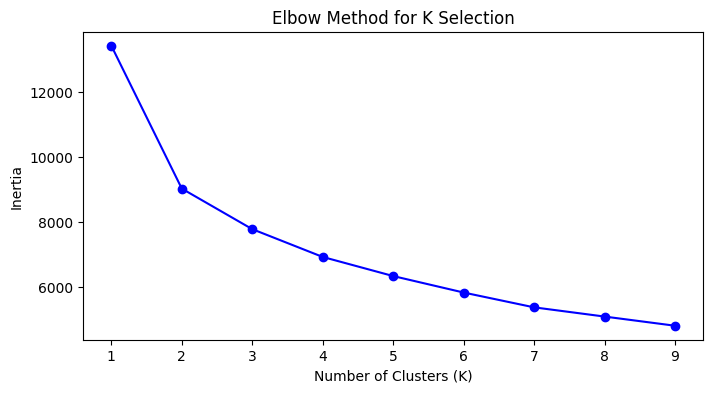

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o', color='b')
plt.title('Elbow Method for K Selection')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

For K = 2, Silhouette Score = 0.2991
For K = 3, Silhouette Score = 0.2142
For K = 4, Silhouette Score = 0.2112
For K = 5, Silhouette Score = 0.2111
For K = 6, Silhouette Score = 0.2028
For K = 7, Silhouette Score = 0.2000
For K = 8, Silhouette Score = 0.2030
For K = 9, Silhouette Score = 0.2055


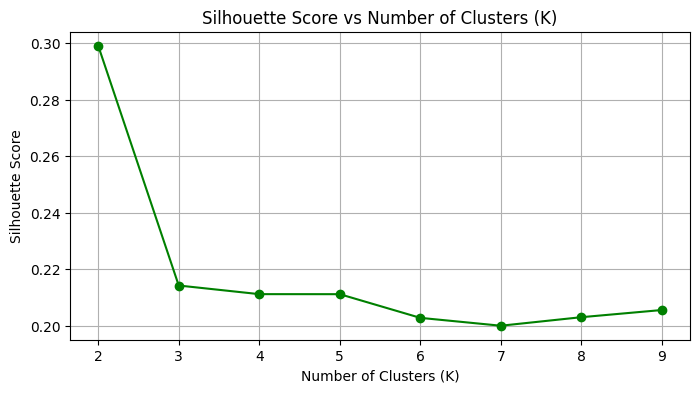

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_range= range(2,10)

for k in k_range:
  kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans_temp.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, cluster_labels)
  silhouette_scores.append(score)
  print(f"For K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='green')
plt.title('Silhouette Score vs Number of Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

K-Means Cluster Counts:
KMeans_Cluster
2    862
1    695
0    679
Name: count, dtype: int64


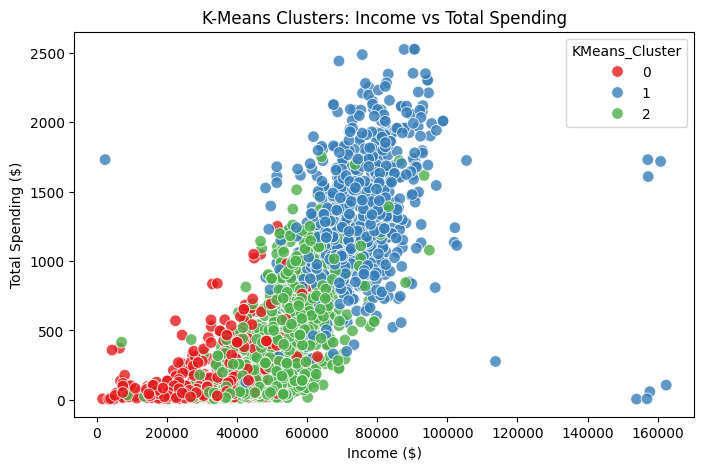

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(X['KMeans_Cluster'].value_counts())

# Quick 2D Visualization of K-Means Clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='Income',
    y='Total_Spending',
    hue='KMeans_Cluster',
    data=X,
    palette='Set1',
    s=70,
    alpha=0.8
)
plt.title('K-Means Clusters: Income vs Total Spending')
plt.xlabel('Income ($)')
plt.ylabel('Total Spending ($)')
plt.show()

DBSCAN Cluster Counts (-1 represents noise/outliers):
DBSCAN_Cluster
 2    1117
 0     617
 1     412
-1      49
 3      34
 4       7
Name: count, dtype: int64


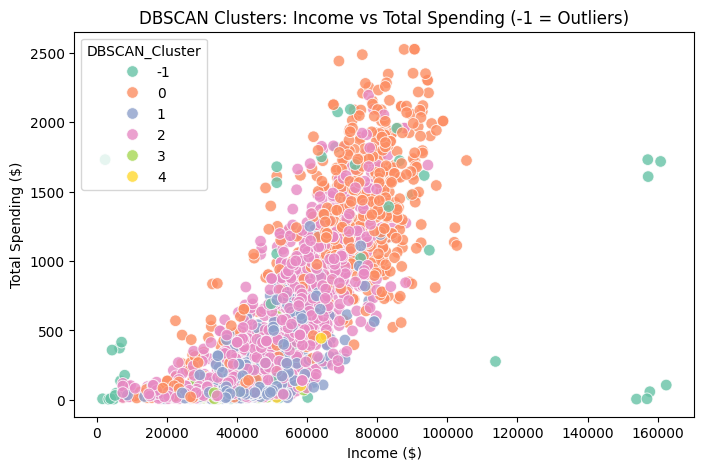

In [ ]:
dbscan = DBSCAN(eps=1.2, min_samples=5)
X['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("DBSCAN Cluster Counts (-1 represents noise/outliers):")
print(X['DBSCAN_Cluster'].value_counts())

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='Income',
    y='Total_Spending',
    hue='DBSCAN_Cluster',
    data=X,
    palette='Set2',
    s=70,
    alpha=0.8
)
plt.title('DBSCAN Clusters: Income vs Total Spending (-1 = Outliers)')
plt.xlabel('Income ($)')
plt.ylabel('Total Spending ($)')
plt.show()

In [22]:
%cd /content

!git add .
!git commit -m "Update project"
!git push --force origin main

/content
On branch main
nothing to commit, working tree clean
fatal: could not read Username for 'https://github.com': No such device or address
